# Meta-LSQ: Meta-Learned Surrogates with Gradient Observations

- Contributors: sulcantonin
- Last updated: Nov 19, 2026
- BoTorch version: 0.18.2.dev52 (commit e95ccc2a), GPyTorch 1.15.2, PyTorch 2.15.0

Meta-LSQ [1] is a surrogate for Bayesian optimization of a *family* of related
objectives, such as one machine or simulator under changing conditions or targets.
Each task is fitted by a single regularised least-squares solve over a frozen basis
of random Fourier features. Only three scalars are learned, and they are learned
once, across tasks of the family: the bandwidth, the ridge, and the weight of
gradient observations. The derivative of a sinusoid is again a sinusoid, so the
same solve can also use gradient observations. These are cheap when the objective
comes from a differentiable simulator.

The fitted model is Bayesian linear regression, so `MetaLSQModel` returns a Gaussian
posterior and works with BoTorch's acquisition functions, including fantasy-based
ones such as knowledge gradient. Conditioning on a task's data is one Cholesky
factorisation; there is no per-task hyperparameter fitting.

This notebook meta-trains Meta-LSQ on a family of perturbed Hartmann-3 functions
and runs BO on held-out tasks of the family. It compares Meta-LSQ with a GP fitted
per task on values, and with a GP fitted per task on values and gradients
(gradient-enhanced kriging, GEK).

**When it fits, and when not.** Meta-LSQ needs data from a family of related
tasks for meta-training. It is aimed at smooth objectives in a few dimensions.
Inputs and outcomes must keep the scale used in meta-training: the learned scalars
refer to that scale, so do not standardise each task separately. The method does
poorly on non-smooth objectives [1].

[1] A. Sulc. Meta-LSQ: A Closed-Form Sobolev Inner Solver for Few-Shot
Meta-Learning. Proceedings of the Northern Lights Deep Learning Conference, PMLR
352, 2027. Code: https://github.com/sulcantonin/metalsq-public

In [1]:
import warnings

warnings.filterwarnings("ignore")

import math  # noqa: E402
import time  # noqa: E402

import matplotlib.pyplot as plt
import torch
from botorch.acquisition import LogExpectedImprovement
from botorch.exceptions import ModelFittingError
from botorch.fit import fit_gpytorch_mll
from botorch.models import SingleTaskGP
from botorch.models.model import Model
from botorch.optim import optimize_acqf
from botorch.posteriors.gpytorch import GPyTorchPosterior
from botorch_community.models.meta_lsq import MetaLSQ, MetaLSQTask
from gpytorch.distributions import MultitaskMultivariateNormal, MultivariateNormal
from gpytorch.kernels import RBFKernelGrad, ScaleKernel
from gpytorch.likelihoods import MultitaskGaussianLikelihood
from gpytorch.means import ConstantMeanGrad
from gpytorch.mlls import ExactMarginalLogLikelihood
from gpytorch.models import ExactGP
from torch.quasirandom import SobolEngine

torch.set_default_dtype(torch.float64)

## The task family

Each task is the Hartmann-3 function with its four bump heights scaled by up to
20% and its bump centres moved by up to 0.1 in each coordinate. The objective is
maximised on the unit cube. Gradients come from autograd, standing in for a
differentiable simulator. The maximum of each held-out task is found numerically
to compute the regret.

In [2]:
ALPHA = torch.tensor([1.0, 1.2, 3.0, 3.2])
A_H3 = torch.tensor([[3.0, 10, 30], [0.1, 10, 35], [3.0, 10, 30], [0.1, 10, 35]])
P_H3 = 1e-4 * torch.tensor(
    [[3689, 1170, 2673], [4699, 4387, 7470], [1091, 8732, 5547], [381, 5743, 8828]]
)
DIM = 3


def sample_task(gen):
    """Random task parameters: bump heights scaled by up to 20%, centres moved by up
    to 0.1 in each coordinate."""
    alpha = ALPHA * (0.8 + 0.4 * torch.rand(4, generator=gen))
    centres = P_H3 + 0.2 * (torch.rand(4, DIM, generator=gen) - 0.5)
    return alpha, centres


def f(params, X):
    """The task's objective (to be maximised) at ``X`` (``n x 3``), as ``n x 1``."""
    alpha, centres = params
    sq = ((X.unsqueeze(-2) - centres) ** 2 * A_H3).sum(-1)  # n x 4
    return (alpha * torch.exp(-sq)).sum(-1, keepdim=True)


def f_and_grad(params, X):
    """Values ``n x 1`` and gradients ``n x 1 x 3``."""
    X = X.detach().clone().requires_grad_(True)
    Y = f(params, X)
    (G,) = torch.autograd.grad(Y.sum(), X)
    return Y.detach(), G.unsqueeze(-2)


def task_maximum(params):
    """The task's maximum, from a dense Sobol grid refined by projected gradient
    ascent."""
    X = SobolEngine(DIM, scramble=True, seed=0).draw(2**14)
    top = X[f(params, X)[:, 0].topk(16).indices].clone().requires_grad_(True)
    opt = torch.optim.Adam([top], lr=1e-3)
    for _ in range(300):
        opt.zero_grad()
        (-f(params, top).sum()).backward()
        opt.step()
        with torch.no_grad():
            top.clamp_(0, 1)
    return f(params, top.detach()).max().item()

## Meta-training data

A meta-training task has 3 to 20 random support points, with values and gradients,
and 100 query points. Meta-training minimises the query error after the
closed-form fit, differentiating through the solve.

In [3]:
def meta_task(gen, grad=True):
    params = sample_task(gen)
    n = int(torch.randint(3, 21, (1,), generator=gen))
    X = torch.rand(n, DIM, generator=gen)
    Xq = torch.rand(100, DIM, generator=gen)
    Y, dY = f_and_grad(params, X)
    return MetaLSQTask(X, Y, Xq, f(params, Xq), dY if grad else None)

## Meta-training

We train five variants and compare them on 200 validation tasks, which are separate
from the held-out tasks used for BO below.

- `prior_mean=True` meta-learns coefficients that the ridge shrinks towards, i.e.
  what all tasks of the family share.
- `ard=True` learns one bandwidth per input. The Hartmann bumps are much narrower
  along some inputs than others, and the gradients along those inputs are larger.
- `value_warmup_steps` leaves the gradients out for the first half of
  meta-training. Here the gradients are up to about six times larger than the
  values; without a warm-up, training can settle on a bandwidth that is too small.

For each kind of data (values only, values and gradients), the variant with the
lower validation error is used for BO.

In [4]:
STEPS = 4000


def train(use_gradients, ard, prior_mean, warmup=0):
    meta = MetaLSQ(
        dim=DIM, use_gradients=use_gradients, ard=ard, prior_mean=prior_mean
    )
    t0 = time.time()
    meta.meta_fit(
        lambda k, g: [meta_task(g, use_gradients) for _ in range(k)],
        num_steps=STEPS,
        batch_size=8,
        lr=1e-2,
        value_warmup_steps=warmup,
    )
    return meta, time.time() - t0


val_gen = torch.Generator().manual_seed(1)
val_tasks = [meta_task(val_gen) for _ in range(200)]


def val_loss(meta):
    tasks = val_tasks
    if not meta.use_gradients:
        tasks = [MetaLSQTask(t.train_X, t.train_Y, t.test_X, t.test_Y) for t in tasks]
    with torch.no_grad():
        return meta.query_loss(tasks).item()


VARIANTS = {
    # name: (use_gradients, ard, prior_mean, value warm-up steps)
    "values": (False, False, False, 0),
    "values, prior mean": (False, False, True, 0),
    "values, prior mean, ARD": (False, True, True, 0),
    "gradients, prior mean, ARD": (True, True, True, 0),
    "gradients, prior mean, ARD, warm-up": (True, True, True, STEPS // 2),
}
trained = {}
for name, config in VARIANTS.items():
    meta, secs = train(*config)
    trained[name] = meta
    print(f"{name:37} {secs:4.1f} s  validation MSE {val_loss(meta):.4f}")
    print(f"{'':37} {meta.extra_repr()}")

values                                19.8 s  validation MSE 0.5475
                                      sigma=3.634, mu=0.000589, N=200, d=3, m=1


values, prior mean                    17.2 s  validation MSE 0.1293
                                      sigma=4.646, mu=0.000259, N=200, d=3, m=1


values, prior mean, ARD               19.1 s  validation MSE 0.0963
                                      sigma=[1.03, 4.31, 5.65], mu=0.00117, N=200, d=3, m=1


gradients, prior mean, ARD            27.4 s  validation MSE 0.3329
                                      sigma=[0.126, 1.23, 0.57], mu=0.0268, w=0.01207, N=200, d=3, m=1


gradients, prior mean, ARD, warm-up   19.1 s  validation MSE 0.0446
                                      sigma=[1.33, 4.02, 6.88], mu=0.0068, w=0.00697, N=200, d=3, m=1


In [5]:
meta_values = min(
    (m for m in trained.values() if not m.use_gradients), key=val_loss
)
meta_grads = min((m for m in trained.values() if m.use_gradients), key=val_loss)
print("values only:    ", meta_values)
print("with gradients: ", meta_grads)

values only:     MetaLSQ(sigma=[1.03, 4.31, 5.65], mu=0.00117, N=200, d=3, m=1)
with gradients:  MetaLSQ(sigma=[1.33, 4.02, 6.88], mu=0.0068, w=0.00697, N=200, d=3, m=1)


## Baseline: a GP on values and gradients

The fair baseline for a model that uses gradients is a GP that uses them too.
GPyTorch provides `RBFKernelGrad` for this. We fit it per task by maximising the
marginal likelihood and wrap it so that BoTorch sees the posterior over the value
only.

In [6]:
class GEK(ExactGP):
    """An exact GP on values and gradients (gradient-enhanced kriging), refitted per
    task by maximising the marginal likelihood."""

    def __init__(self, X, Y, dY):
        y_mean, y_std = Y.mean(), Y.std().clamp_min(1e-6)
        targets = torch.cat([Y - y_mean, dY[:, 0, :]], dim=-1) / y_std
        likelihood = MultitaskGaussianLikelihood(num_tasks=DIM + 1)
        super().__init__(X, targets, likelihood)
        self.y_mean, self.y_std = y_mean, y_std
        self.mean_module = ConstantMeanGrad()
        self.covar_module = ScaleKernel(RBFKernelGrad(ard_num_dims=DIM))

    def transform_inputs(self, X):  # read by botorch's fit_gpytorch_mll
        return X

    def forward(self, X):
        return MultitaskMultivariateNormal(self.mean_module(X), self.covar_module(X))


class GEKModel(Model):
    """BoTorch wrapper: the posterior over the value output only. If fitting fails
    (it can when points cluster near the optimum), the hyperparameters of the
    previous step are kept."""

    failures = 0

    def __init__(self, X, Y, dY, previous=None):
        super().__init__()
        self.gp = GEK(X, Y, dY)
        if previous is not None:
            self.gp.load_state_dict(previous.gp.state_dict(), strict=False)
        mll = ExactMarginalLogLikelihood(self.gp.likelihood, self.gp)
        try:
            fit_gpytorch_mll(mll)
        except ModelFittingError:
            GEKModel.failures += 1
            if previous is not None:
                self.gp.load_state_dict(previous.gp.state_dict(), strict=False)
        self.gp.eval()

    num_outputs = 1

    def posterior(self, X, output_indices=None, observation_noise=False, **kwargs):
        mvn = self.gp(X)  # b x q x (d + 1), interleaved per point
        q = X.shape[-2]
        mean = mvn.mean[..., 0] * self.gp.y_std + self.gp.y_mean
        idx = torch.arange(q) * (DIM + 1)
        covar = mvn.lazy_covariance_matrix[..., idx, :][..., idx].to_dense()
        return GPyTorchPosterior(MultivariateNormal(mean, covar * self.gp.y_std**2))

## Bayesian optimization on held-out tasks

Every method starts from the same 3 Sobol points per task and then takes 20 steps
of analytic log expected improvement. The two GPs are refitted at every step; the
Meta-LSQ models are only conditioned on the data.

In [7]:
BOUNDS = torch.stack([torch.zeros(DIM), torch.ones(DIM)])


def fit_model(method, X, Y, dY, previous=None):
    if method == "GP (values)":
        model = SingleTaskGP(X, Y)
        fit_gpytorch_mll(ExactMarginalLogLikelihood(model.likelihood, model))
        return model
    if method == "GEK (values + gradients)":
        return GEKModel(X, Y, dY, previous)
    if method == "Meta-LSQ (values)":
        return meta_values.condition(X, Y)
    return meta_grads.condition(X, Y, dY)


METHODS = [
    "GP (values)",
    "Meta-LSQ (values)",
    "GEK (values + gradients)",
    "Meta-LSQ (values + gradients)",
]
N_INIT, N_ITER, N_TASKS = 3, 20, 20


def run_bo(params, method, seed):
    torch.manual_seed(seed)  # the acquisition optimiser's random restarts
    X = SobolEngine(DIM, scramble=True, seed=seed).draw(N_INIT)
    Y, dY = f_and_grad(params, X)
    seconds, model = 0.0, None
    for _ in range(N_ITER):
        t0 = time.time()
        model = fit_model(method, X, Y, dY, model)
        seconds += time.time() - t0
        acqf = LogExpectedImprovement(model, best_f=Y.max())
        x, _ = optimize_acqf(acqf, BOUNDS, q=1, num_restarts=4, raw_samples=128)
        y, dy = f_and_grad(params, x)
        X, Y, dY = torch.cat([X, x]), torch.cat([Y, y]), torch.cat([dY, dy])
    return Y[:, 0].cummax(0).values, seconds / N_ITER


test_gen = torch.Generator().manual_seed(3)
test_tasks = [sample_task(test_gen) for _ in range(N_TASKS)]
maxima = torch.tensor([task_maximum(p) for p in test_tasks])
regret, fit_time = {}, {}
for method in METHODS:
    traces, times = [], []
    for i, params in enumerate(test_tasks):
        best, secs = run_bo(params, method, seed=i)
        traces.append(maxima[i] - best)
        times.append(secs)
    regret[method] = torch.stack(traces)
    fit_time[method] = sum(times) / len(times)
    final = regret[method][:, -1]
    print(
        f"{method:30}  final regret median {final.median():.3g}  "
        f"mean {final.mean():.3g}  model time per step {1e3 * fit_time[method]:.0f} ms"
    )

print(f"GEK fits that failed and kept the previous hyperparameters: {GEKModel.failures}")

GP (values)                     final regret median 0.0107  mean 0.0721  model time per step 73 ms


Meta-LSQ (values)               final regret median 0.00372  mean 0.0167  model time per step 1 ms


GEK (values + gradients)        final regret median 0.000166  mean 0.116  model time per step 52 ms


Meta-LSQ (values + gradients)   final regret median 0.000169  mean 0.00271  model time per step 1 ms
GEK fits that failed and kept the previous hyperparameters: 1


Per task: the regret after 8 evaluations (3 initial points and 5 BO steps),
how many tasks end below a regret of 0.001, and the worst final regret.

In [8]:
print(f"{'':30}  regret after 8 evals   final: tasks < 1e-3   worst task")
for method in METHODS:
    r = regret[method]
    print(
        f"{method:30}  median {r[:, 7].median():9.2e}"
        f"   {int((r[:, -1] < 1e-3).sum()):2d} of {N_TASKS}"
        f"          {r[:, -1].max():.2e}"
    )

                                regret after 8 evals   final: tasks < 1e-3   worst task
GP (values)                     median  4.47e-01    0 of 20          9.11e-01
Meta-LSQ (values)               median  1.01e-01    1 of 20          9.62e-02
GEK (values + gradients)        median  7.26e-02   13 of 20          9.83e-01
Meta-LSQ (values + gradients)   median  1.03e-03   14 of 20          3.97e-02


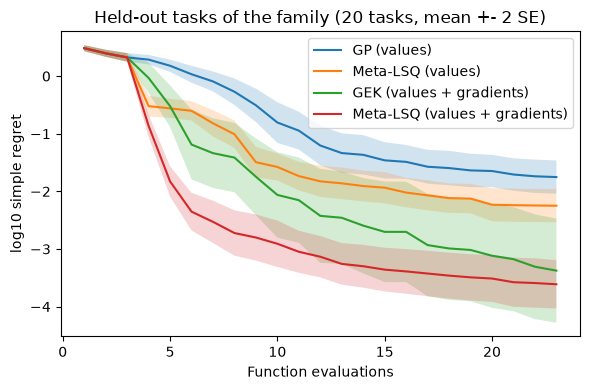

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
evals = torch.arange(1, N_INIT + N_ITER + 1)
for method in METHODS:
    r = regret[method].clamp_min(1e-6).log10()
    m, s = r.mean(0), r.std(0) / math.sqrt(N_TASKS)
    ax.plot(evals, m, label=method)
    ax.fill_between(evals, m - 2 * s, m + 2 * s, alpha=0.2)
ax.set_xlabel("Function evaluations")
ax.set_ylabel("log10 simple regret")
ax.set_title(f"Held-out tasks of the family ({N_TASKS} tasks, mean +- 2 SE)")
ax.legend()
plt.tight_layout()
plt.show()

## Results

On these 20 held-out tasks (one run, printed above):

- **Values only.** Meta-LSQ ends with a lower regret than the GP fitted per task
  (median 0.0037 against 0.0107), and its worst task is far better (0.10 against
  0.91). It needs no hyperparameter fitting per step.
- **Values and gradients.** Meta-LSQ and GEK end with the same median regret
  (0.00017). Meta-LSQ gets there sooner: after 8 evaluations its median regret is
  0.001, against 0.07 for GEK. GEK stays stuck on one task (final regret 0.98),
  which sets its mean; Meta-LSQ's worst task ends at 0.04.
- **Training choices matter.** Without the value warm-up, Meta-LSQ with gradients
  learned a bandwidth far too small and was worse than the values-only model on
  validation (0.33 against 0.10). Per-input bandwidths (`ard=True`) and the prior
  mean each lowered the validation error clearly.

**Caveats.** This is one synthetic family in three dimensions, 20 held-out tasks
and one meta-training seed. The GPs are fitted per task and do not use the other
tasks, so the comparison is between a meta-learned model and per-task models, not
between two meta-learned models. GEK's fit failed once over all its steps (it then
kept the previous hyperparameters). Meta-LSQ needs meta-training data from the
family and inputs and outcomes on the meta-training scale. It is not a replacement
for a GP on a single, unrelated problem.